In [ ]:
# Install Python dependencies (intended for Google Colab).
!pip install geopandas -q
!pip install arviz==0.23.0 -q
!pip install pymc -q
!pip install nutpie -q
!pip install numpyro -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 31.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 105.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 65.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 37.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 25.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 85.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 444.9/444.9 kB 5.8 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Import geospatial, Bayesian modeling, numerical, and plotting libraries.
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
import libpysal.weights as lw
from libpysal.weights import Queen

import os
#import warnings
import arviz as az
import pymc as pm
import pytensor.tensor as pt

import networkx as nx
import nutpie

from sklearn.preprocessing import StandardScaler

from esda.moran import Moran

from scipy import sparse
from scipy.linalg import solve
from scipy.sparse.linalg import spsolve
#warnings.filterwarnings("ignore")

/usr/local/lib/python3.13/dist-packages/arviz/__init__.py:39: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


In [ ]:
# # Record Python and installed library versions for reproducibility.
# import sys

# # Python version
# print(f"Python Version: {sys.version.split(' ')[0]}")

# # Imported libraries versions
# print("\nImported Library Versions:")
# for module_name in sorted(sys.modules.keys()):
#     if any(keyword in module_name for keyword in ['pandas', 'numpy', 'scipy', 'matplotlib', 'geopandas', 'arviz', 'pymc', 'nutpie', 'numpyro', 'libpysal', 'networkx', 'sklearn', 'esda', 'statsmodels']):
#         try:
#             module = sys.modules[module_name]
#             if hasattr(module, '__version__'):
#                 print(f"{module_name}: {module.__version__}")
#         except Exception:
#             # Some modules might cause issues when trying to access __version__ or other attributes
#             pass


In [ ]:
# Optional data import from the source polygon and covariate files; adapt paths to your environment.
#df_gpkg = gpd.read_file("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/京都市国勢統計区.gpkg")
#df = pd.read_excel("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/解析用国勢統計区データ.xlsx")

In [ ]:
# Optional preprocessing: drop nonanalytical geospatial metadata columns.
#df_gpkg = df_gpkg.drop(["Name", "descriptio","timestamp", "begin", "end", "altitudeMo", "tessellate", "extrude", "visibility", "drawOrder", "icon"], axis=1)

In [ ]:
# Optional preprocessing: check that both source tables contain matching unique IDs.

#df["id"] = df["id"].astype(int)
#df_gpkg["id"] = df_gpkg["id"].astype(int)

#assert df["id"].is_unique
#assert df_gpkg["id"].is_unique
#assert set(df["id"]) == set(df_gpkg["id"])

In [ ]:
# Optional one-to-one merge using ID and area name; keep original Japanese column names.
#df_gpkg = df_gpkg.merge(df, on=["id", "名称"], how="left", validate="one_to_one")

In [ ]:
#df_gpkg.crs

In [ ]:
# Optional export of the merged geospatial data for downstream modeling.
#df_gpkg.to_file("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/解析用結合データ.geojson", driver="GeoJSON")

In [ ]:
# Load the prepared area-level geospatial dataset used in this analysis.
#df_gpkg = gpd.read_file("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/解析用結合データ.geojson")

In [ ]:
# Load the prepared area-level geospatial dataset used in this analysis.
df_gpkg = gpd.read_file("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/解析用結合データENG.geojson")

In [ ]:
df_gpkg.head()

,名称,id,国勢統計区,行政区,Number of out-of-hospital natural deaths,Total Population（Offset）,Proportion of men,Proportion of adults aged 65 years or older living alone,Proportion of households living in publicly rented housing,Proportion of foreign residents,...,Less than high school education,Density of healthcare facilities,Density of healthcare facilities (Log-transformed),Density of bus stops,density of bus stops (Log-transformed),Density of railway stations,Density of railway stations (Log-transformed),Missing of land prices,Land prices (Log-transformed),geometry
0,北_待鳳,0,待鳳,北,8,9851,0.477312,0.138616,0.000000,0.019287,...,0.100628,8.866995,2.289195,8.866995,2.289195,0.0,0.0,0,12.441145,"MULTIPOLYGON Z (((135.73814 35.04477 100, 135...."
1,北_紫竹,1,紫竹,北,6,6655,0.462660,0.124963,0.000000,0.017581,...,0.059496,18.739353,2.982614,23.850085,3.212861,0.0,0.0,0,12.660328,"MULTIPOLYGON Z (((135.74857 35.04626 100, 135...."
2,北_紫野,2,紫野,北,4,7685,0.464802,0.162380,0.016603,0.021861,...,0.098716,16.420361,2.857640,8.210181,2.220309,0.0,0.0,0,12.419166,"MULTIPOLYGON Z (((135.74523 35.03544 100, 135...."
3,北_楽只,3,楽只,北,3,2273,0.466344,0.202713,0.223674,0.021557,...,0.149943,8.064516,2.204367,12.096774,2.572366,0.0,0.0,0,12.400817,"MULTIPOLYGON Z (((135.73997 35.03853 100, 135...."
4,北_鷹峯,4,鷹峯,北,7,3989,0.484583,0.143010,0.000000,0.019554,...,0.112549,0.147514,0.137598,0.737572,0.552489,0.0,0.0,0,12.031719,"MULTIPOLYGON Z (((135.71805 35.06987 100, 135...."


In [ ]:
df_gpkg.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [ ]:
# Validate expected geographic area count and ID ordering.
# Validate the expected number of areas, sequential IDs, and unique area names.
assert len(df_gpkg) == 227
assert list(df_gpkg["id"]) == list(range(227))
assert df_gpkg["名称"].is_unique

In [ ]:
# Build queen-neighbor spatial adjacency.
# Construct a queen-contiguity spatial weights matrix (shared edge or vertex).
w_queen = Queen.from_dataframe(df_gpkg, ids=df_gpkg["id"].to_list())

In [ ]:
# Check adjacency IDs against the geographic table.
# Verify that the adjacency-matrix ordering matches the GeoDataFrame IDs.
assert list(w_queen.id_order) == list(df_gpkg["id"])

In [ ]:
# The ICAR precision matrix is singular; the small diagonal perturbation and centering adjustment are used to obtain constrained marginal variances.
# Compute the ICAR scaling factor as the geometric mean of marginal variances under the sum-to-zero constraint.
def scaling_factor_sp(A):
    num_neighbors = A.sum(axis=1)
    A = sparse.csc_matrix(A)
    D = sparse.diags(num_neighbors, format="csc")
    Q = D - A

    Q_perturbed = Q + sparse.diags(np.ones(Q.shape[0])) * max(Q.diagonal()) * np.sqrt(np.finfo(np.float64).eps)

    n = Q_perturbed.shape[0]
    b = sparse.identity(n, format="csc")
    Sigma = spsolve(Q_perturbed, b)
    A = np.ones(n)
    W = Sigma @ A.T
    Q_inv = Sigma - np.outer(W * solve(A @ W, np.ones(1)), W.T)

    return np.exp(np.sum(np.log(np.diag(Q_inv))/n))

In [ ]:
# Convert queen contiguity to an adjacency array and compute the scaling factor.
w_queen_np = w_queen.full()[0]
scaling_factor = scaling_factor_sp(w_queen_np)
print(scaling_factor)

0.38976731151419813


In [ ]:
# Inspect available geospatial and covariate columns.
df_gpkg.columns

Index(['名称', 'id', '国勢統計区', '行政区', 'Number of out-of-hospital natural deaths',
       'Total Population（Offset）', 'Proportion of men',
       'Proportion of adults aged 65 years or older living alone',
       'Proportion of households living in publicly rented housing',
       'Proportion of foreign residents',
       'Proportion of mother-child households', 'Unemployment rate',
       'Proportion of short-term residents', 'Less than high school education',
       'Density of healthcare facilities',
       'Density of healthcare facilities (Log-transformed)',
       'Density of bus stops', 'density of bus stops (Log-transformed)',
       'Density of railway stations',
       'Density of railway stations (Log-transformed)',
       'Missing of land prices', 'Land prices (Log-transformed)', 'geometry'],
      dtype='object')

In [ ]:
# Prepare standardized predictors, a missingness indicator, death counts, and the log-population offset.
scaler = StandardScaler()

covariate_cols = [
    "Proportion of men",
    "Proportion of adults aged 65 years or older living alone",
    "Proportion of households living in publicly rented housing",
    "Proportion of foreign residents",
    "Proportion of mother-child households",
    "Unemployment rate",
    "Proportion of short-term residents",
    "Less than high school education",
    "Density of healthcare facilities (Log-transformed)",
    "density of bus stops (Log-transformed)",
    "Density of railway stations (Log-transformed)",
    "Land prices (Log-transformed)"]

indicator_cols = ["Missing of land prices"]

X_cont = scaler.fit_transform(df_gpkg[covariate_cols])
X_indicator = df_gpkg[indicator_cols].to_numpy()

X = np.column_stack([X_cont, X_indicator])

y = df_gpkg["Number of out-of-hospital natural deaths"].to_numpy()
off_set = np.log(df_gpkg["Total Population（Offset）"].to_numpy())

model_cols = covariate_cols + indicator_cols

In [ ]:
# Display predictor names used by the model.
model_cols

['Proportion of men',
 'Proportion of adults aged 65 years or older living alone',
 'Proportion of households living in publicly rented housing',
 'Proportion of foreign residents',
 'Proportion of mother-child households',
 'Unemployment rate',
 'Proportion of short-term residents',
 'Less than high school education',
 'Density of healthcare facilities (Log-transformed)',
 'density of bus stops (Log-transformed)',
 'Density of railway stations (Log-transformed)',
 'Land prices (Log-transformed)',
 'Missing of land prices']

In [ ]:
# Define the negative-binomial BYM2 likelihood, allowing variance greater than the mean.
# Define the BYM2 hierarchical count model.
n_area = len(y)
n_cov = X.shape[1]

coords = {"area": np.arange(n_area), "covariate": model_cols}

with pm.Model(coords=coords) as bym2_model:
    # Register predictors, observed counts, and population offset as model data.
    X_data = pm.Data("X_data", X, dims=("area", "covariate"))
    y_obs = pm.Data("y_obs", y, dims="area")
    offset_data = pm.Data("offset_data", off_set, dims="area")

    # Specify priors for the intercept and fixed-effect coefficients.
    intercept = pm.Normal("intercept", mu=0, sigma=1)
    beta = pm.Normal("beta", mu=0, sigma=1, dims="covariate")

    # Specify the mixing parameter for spatially structured versus unstructured effects.
    rho = pm.Beta("rho", 0.5, 0.5)

    # Define the spatially structured intrinsic CAR (ICAR) effect.
    phi = pm.ICAR("phi", W=w_queen_np, dims="area")

    # Define independent area-specific random effects.
    theta = pm.Normal("theta", mu=0, sigma=1, dims="area")

    # Assign a prior to the overall BYM2 random-effect scale.
    sigma = pm.HalfNormal("sigma", sigma=1)

    # Combine scaled structured and unstructured spatial effects.
    mixture = pm.Deterministic("mixture", pt.sqrt(1 - rho) * theta + pt.sqrt(rho / scaling_factor) * phi, dims="area")

    # Use a log link with an offset for the population at risk.
    mu = pm.Deterministic("mu", pt.exp(intercept + offset_data + pm.math.dot(X_data, beta) + sigma * mixture), dims="area")

    alpha = pm.HalfNormal("alpha", sigma=5)

    y_i = pm.NegativeBinomial("y_i", mu=mu, alpha=alpha, observed=y_obs, dims="area")

In [ ]:
# Draw MCMC samples with a fixed random seed; inspect diagnostics in subsequent cells.
with bym2_model:
    idata = pm.sample(chains=4,
                      target_accept=0.95,
                      tune=3000,
                      draws=3000,
                      #nuts_sampler="numpyro",
                      random_seed=123)

Output()

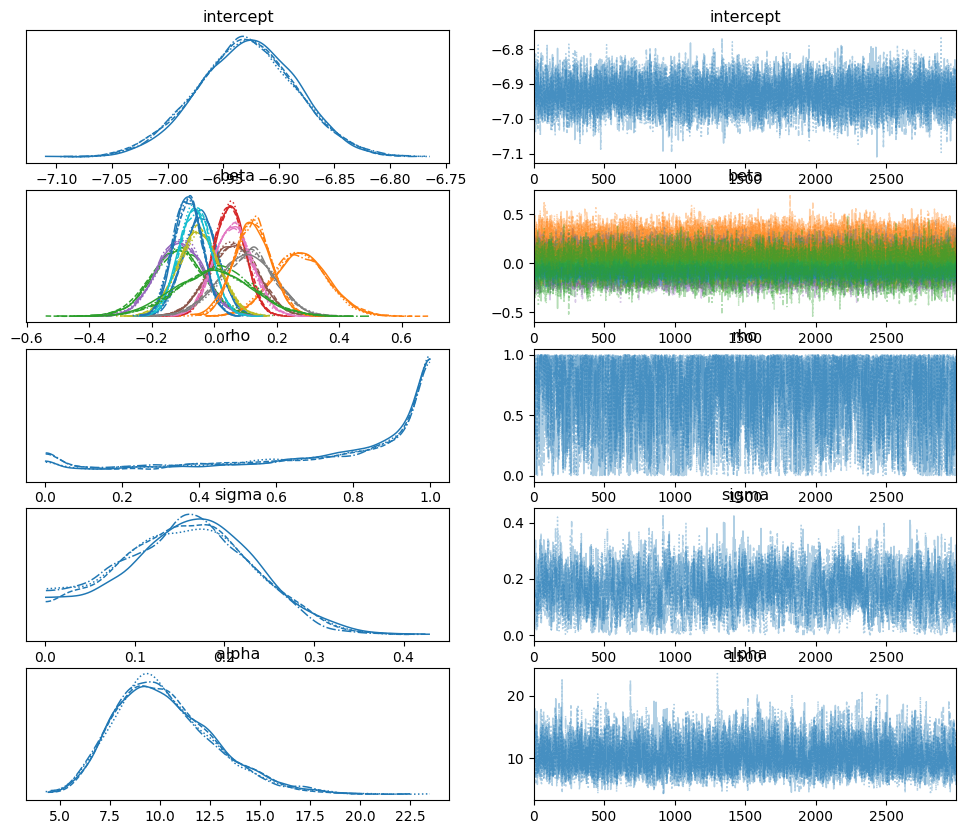

In [ ]:
# Plot posterior traces for model parameters.
az.plot_trace(idata, var_names=["intercept", "beta", "rho", "sigma", "alpha"]);

In [ ]:
# Identify parameters with potentially problematic R-hat values.
summary = az.summary(idata)
summary[summary["r_hat"] > 1.01].sort_values("r_hat", ascending=False)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat


In [ ]:
# Summarize R-hat and effective sample size diagnostics.
print("max r_hat:", summary["r_hat"].max())
print("n r_hat > 1.01:", (summary["r_hat"] > 1.01).sum())
print("n r_hat is NaN:", summary["r_hat"].isna().sum())

print("ess bulk:", summary["ess_bulk"].min())
print("ess tail:", summary["ess_tail"].min())

print("diverging:", idata.sample_stats["diverging"].sum().values)

max r_hat: 1.01
n r_hat > 1.01: 0
n r_hat is NaN: 0
ess bulk: 777.0
ess tail: 895.0
diverging: 0


In [ ]:
# Report posterior summaries with 95% highest-density intervals.
az.summary(idata, var_names=["intercept", "beta", "rho", "sigma", "alpha"], hdi_prob=0.95)

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
intercept,-6.929,0.045,-7.016,-6.841,0.001,0.000,5392.0,8413.0,1.0
beta[Proportion of men],-0.044,0.055,-0.149,0.067,0.001,0.000,6065.0,7754.0,1.0
beta[Proportion of adults aged 65 years or older living alone],0.275,0.088,0.098,0.445,0.001,0.001,3712.0,7246.0,1.0
beta[Proportion of households living in publicly rented housing],-0.116,0.084,-0.284,0.049,0.001,0.001,3737.0,6274.0,1.0
beta[Proportion of foreign residents],0.048,0.050,-0.052,0.144,0.001,0.000,6164.0,7745.0,1.0
beta[Proportion of mother-child households],-0.111,0.073,-0.252,0.034,0.001,0.001,4417.0,6340.0,1.0
beta[Unemployment rate],0.060,0.077,-0.084,0.217,0.001,0.001,7368.0,8527.0,1.0
beta[Proportion of short-term residents],0.059,0.061,-0.058,0.180,0.001,0.001,3874.0,7140.0,1.0
beta[Less than high school education],0.104,0.088,-0.066,0.280,0.001,0.001,4597.0,6764.0,1.0
beta[Density of healthcare facilities (Log-transformed)],-0.050,0.066,-0.174,0.084,0.001,0.001,3466.0,7031.0,1.0


In [ ]:
# Generate posterior predictive death counts for model checking.
with bym2_model:
    idata_nb = pm.sample_posterior_predictive(idata, var_names=["y_i"], predictions=False, extend_inferencedata=True, random_seed=123)


Output()

In [ ]:
# Save the complete ArviZ inference data to NetCDF.
idata.to_netcdf("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/inference_data_nb.nc")

'/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/inference_data_nb.nc'

In [ ]:
# Repeat sampling with an alternative seed as a replication / sensitivity check.
with bym2_model:
    idata2 = pm.sample(chains=4,
                      target_accept=0.95,
                      tune=3000,
                      draws=3000,
                      #nuts_sampler="numpyro",
                      random_seed=321)

Output()

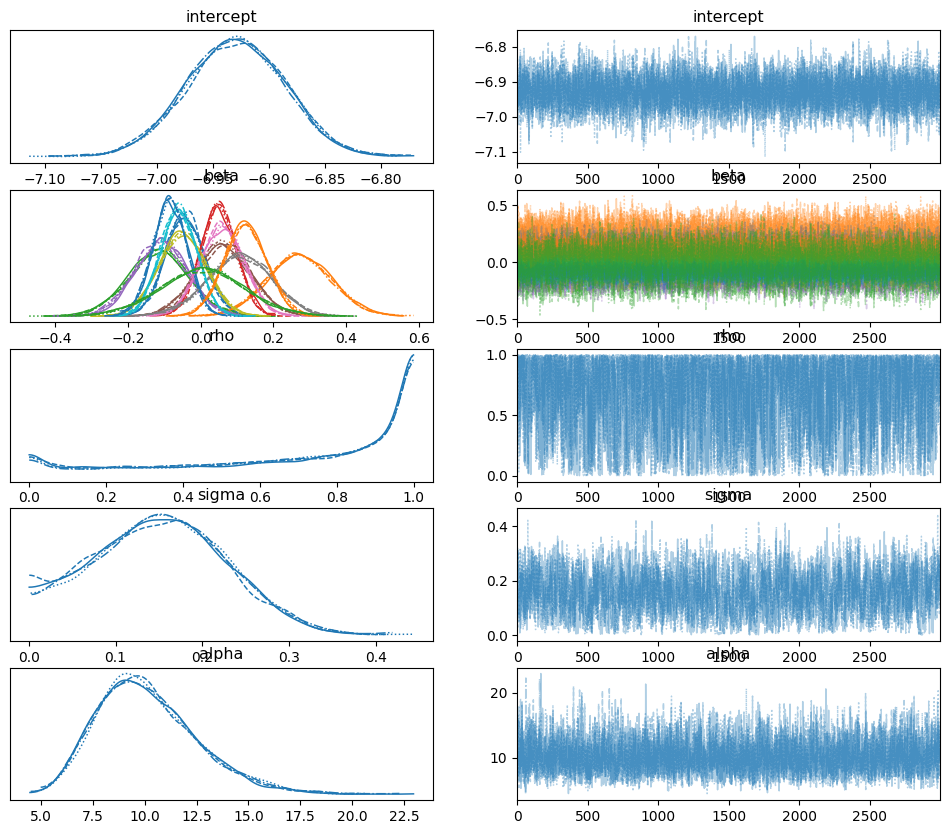

In [ ]:
# Plot trace diagnostics for the repeated MCMC fit.
az.plot_trace(idata2, var_names=["intercept", "beta", "rho", "sigma", "alpha"]);

In [ ]:
# Flag repeated-fit parameters whose R-hat exceeds 1.01.
summary2 = az.summary(idata2)
summary2[summary2["r_hat"] > 1.01].sort_values("r_hat", ascending=False)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat


In [ ]:
# Inspect effective sample size and R-hat for the repeated fit.
print("max r_hat:", summary2["r_hat"].max())
print("n r_hat > 1.01:", (summary2["r_hat"] > 1.01).sum())
print("n r_hat is NaN:", summary2["r_hat"].isna().sum())

print("ess bulk:", summary2["ess_bulk"].min())
print("ess tail:", summary2["ess_tail"].min())

print("diverging:", idata2.sample_stats["diverging"].sum().values)

max r_hat: 1.01
n r_hat > 1.01: 0
n r_hat is NaN: 0
ess bulk: 943.0
ess tail: 1111.0
diverging: 0


In [ ]:
# Report parameter estimates for the repeated fit.
az.summary(idata2, var_names=["intercept", "beta", "rho", "sigma", "alpha"], hdi_prob=0.95)

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
intercept,-6.930,0.044,-7.019,-6.846,0.001,0.000,5742.0,7133.0,1.0
beta[Proportion of men],-0.044,0.054,-0.148,0.064,0.001,0.000,6886.0,8358.0,1.0
beta[Proportion of adults aged 65 years or older living alone],0.271,0.088,0.101,0.449,0.002,0.001,3347.0,6184.0,1.0
beta[Proportion of households living in publicly rented housing],-0.117,0.084,-0.280,0.050,0.001,0.001,3192.0,6856.0,1.0
beta[Proportion of foreign residents],0.049,0.049,-0.048,0.145,0.001,0.000,5931.0,7819.0,1.0
beta[Proportion of mother-child households],-0.110,0.073,-0.257,0.030,0.001,0.001,3466.0,7609.0,1.0
beta[Unemployment rate],0.061,0.076,-0.088,0.212,0.001,0.001,6160.0,7810.0,1.0
beta[Proportion of short-term residents],0.059,0.061,-0.059,0.175,0.001,0.000,4568.0,7157.0,1.0
beta[Less than high school education],0.106,0.089,-0.071,0.278,0.001,0.001,4850.0,8448.0,1.0
beta[Density of healthcare facilities (Log-transformed)],-0.050,0.065,-0.179,0.074,0.001,0.001,4501.0,7745.0,1.0


In [ ]:
# Generate posterior predictive samples from the repeated fit.
with bym2_model:
    idata_nb_2 = pm.sample_posterior_predictive(idata2, var_names=["y_i"], predictions=False, extend_inferencedata=True, random_seed=123)

Output()

In [ ]:
# Save the repeated fit as NetCDF.
idata_nb_2.to_netcdf("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/inference_data_nb_2.nc")

'/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/inference_data_nb_2.nc'

In [ ]:
# Calculate variance inflation factors (VIFs) to screen the predictors for multicollinearity.
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

X_vif = pd.DataFrame(X_cont, columns=covariate_cols)

vif_df = pd.DataFrame({
    "variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

vif_df.sort_values("VIF", ascending=False)

,variable,VIF
2,Proportion of households living in publicly re...,3.886277
1,Proportion of adults aged 65 years or older li...,3.804610
7,Less than high school education,2.946729
5,Unemployment rate,2.529004
4,Proportion of mother-child households,2.417066
8,Density of healthcare facilities (Log-transfor...,2.355626
6,Proportion of short-term residents,1.920940
11,Land prices (Log-transformed),1.765365
3,Proportion of foreign residents,1.628820
0,Proportion of men,1.623995
